# Las 28 combinaciones del Entregable 2

La guía del Entregable 2 pide, para regresión, **7 modelos base** (KNN, Ridge, Lasso, Decision Tree, Random Forest, XGBoost y SVR) combinados con **4 métodos de optimización** (Grid Search, Random Search, Bayesiano y Genético): $7 \times 4 = 28$ combinaciones. El balanceo de clases no aplica en regresión. Este capítulo las corre sobre el problema de energía con el mismo protocolo de ATER, elige la mejor combinación de cada modelo y la compara con ATER.

## Protocolo
- **Validación anidada temporal.** Bucle externo: folds 1 a 4 de la ventana creciente con purga de 48 h, los mismos que usa ATER en el capítulo 6. Bucle interno: dentro del entrenamiento de cada fold externo, el último 20 % (con purga de 48 h) es la validación donde el optimizador evalúa sus candidatos. La métrica que se reporta es la del bucle externo, nunca la del interno.
- **Presupuesto igual:** 12 evaluaciones por fold externo para cada optimizador, para comparar calidad por unidad de cómputo.
- **Sin fuga de información:** el escalado va dentro del pipeline y se ajusta solo con el entrenamiento de cada evaluación. Todos los modelos usan el objetivo relativo (demanda / media de 7 días), como los árboles del proyecto.
- **Semilla global 2026** en numpy, scikit-learn, XGBoost, Optuna y el algoritmo genético.

## Optimizadores
| Método | Implementación | Detalle |
|---|---|---|
| Grid Search | malla regular en el cubo unitario del espacio | niveles por dimensión $\lfloor 12^{1/d} \rfloor$; si la malla supera 12 puntos se toman 12 equiespaciados |
| Random Search | muestreo uniforme (o log-uniforme) | 12 puntos |
| Bayesiano | Optuna, *Tree-structured Parzen Estimator* | modelo sustituto TPE (densidades $l(x)$ y $g(x)$ de configuraciones buenas y malas); función de adquisición: mejora esperada, equivalente a maximizar $l(x)/g(x)$; 4 evaluaciones iniciales aleatorias (exploración) y 8 guiadas (explotación) |
| Genético | programado a mano con numpy | población de 4, 3 generaciones; selección por torneo ($k=2$); cruce uniforme ($p=0{,}8$); mutación gaussiana ($p=0{,}3$, $\sigma=0{,}15$ en el cubo unitario); elitismo de 1 individuo; se registra la diversidad genética |

## Espacios de búsqueda y complejidad
| Modelo | Hiperparámetros (rango) | Entrenamiento | Inferencia |
|---|---|---|---|
| KNN | vecinos 3–100 (log), pesos {uniforme, distancia}, $p \in \{1,2\}$ | $O(1)$ (guarda los datos; con árbol KD, $O(n \log n)$) | $O(n\,p)$ por consulta (fuerza bruta) |
| Ridge | $\alpha$ $10^{-3}$–$10^{3}$ (log) | $O(n\,p^2 + p^3)$ | $O(p)$ |
| Lasso | $\alpha$ $10^{-6}$–$10^{-1}$ (log) | $O(n\,p)$ por iteración (descenso por coordenadas) | $O(p)$ |
| Decision Tree | profundidad 3–25, hoja mínima 5–300 (log) | $O(p\,n \log n)$ | $O(\text{profundidad})$ |
| Random Forest | 100 árboles, muestra 50 %; profundidad 6–30, hoja 1–50 (log), fracción de variables 0,2–1 | $O(T\,p'\,n \log n)$ | $O(T \cdot \text{profundidad})$ |
| XGBoost (`hist`) | profundidad 2–10, tasa 0,01–0,3 (log), árboles 100–800 (log), peso mínimo 1–100 (log), submuestra 0,5–1 | $O(T\,p\,n)$ con histogramas | $O(T \cdot \text{profundidad})$ |
| SVR (Nyström + lineal) | $C$ $10^{-2}$–$10^{2}$ (log), $\gamma$ $10^{-3}$–1 (log), $\varepsilon$ 0–0,05 | $O(n\,m^2)$ con $m=300$ componentes, en vez de $O(n^2)$–$O(n^3)$ del kernel exacto | $O(m\,p)$ |

El SVR con kernel RBF exacto no es viable con ~30.000 filas de entrenamiento; la aproximación de Nyström más un SVR lineal (resuelto en el primal) es la alternativa que sugiere la guía. El random forest usa 100 árboles con muestras del 50 % para que las 28 combinaciones quepan en el presupuesto de cómputo.

In [1]:
import sys, json, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src"); import estilo_tablas; estilo_tablas.activar()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)
R = "../resultados/"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
comb = pd.read_csv(R + "e2_combinaciones.csv")
print("Combinaciones evaluadas:", len(comb), "| evaluaciones totales del bucle interno:", int(comb.evaluaciones.sum()))
tab = comb.assign(MSE=lambda d: d.MSE_media.round(0).astype(int).astype(str) + " ± " + d.MSE_de.round(0).astype(int).astype(str))
tab.pivot(index="modelo", columns="optimizador", values="MSE")

Combinaciones evaluadas: 28 | evaluaciones totales del bucle interno: 1228


optimizador,Bayesiano (Optuna TPE),Genético,Grid Search,Random Search
modelo,,,,
Decision Tree,2956 ± 938,3005 ± 1015,3080 ± 982,3037 ± 890
KNN,2529 ± 882,2559 ± 848,2535 ± 876,2482 ± 900
Lasso,2803 ± 933,2814 ± 932,2788 ± 947,2824 ± 928
Random Forest,2271 ± 828,2276 ± 792,2259 ± 818,2279 ± 811
Ridge,2800 ± 940,2803 ± 944,2800 ± 942,2800 ± 940
SVR,2502 ± 763,2615 ± 671,2493 ± 848,2638 ± 767
XGBoost,2289 ± 802,2324 ± 754,2306 ± 754,2268 ± 783


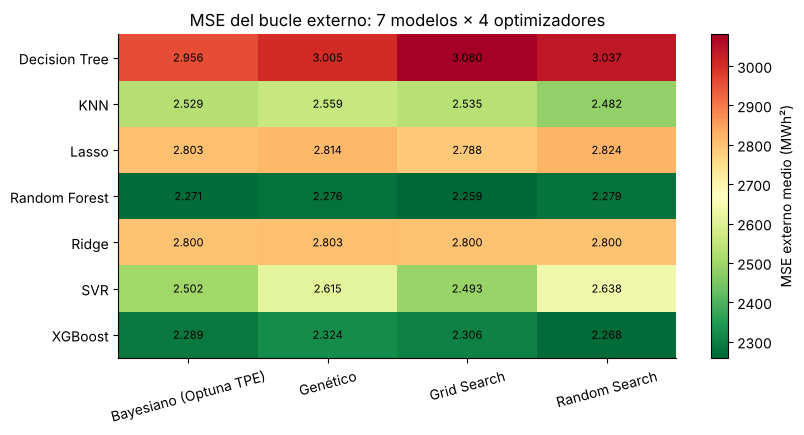

In [3]:
pv = comb.pivot(index="modelo", columns="optimizador", values="MSE_media")
fig, ax = plt.subplots(figsize=(9, 4.2)); im = ax.imshow(pv.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels(pv.columns, rotation=15); ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels(pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]): ax.text(j, i, f"{pv.values[i, j]:,.0f}".replace(",", "."), ha="center", va="center", fontsize=8)
plt.colorbar(im, label="MSE externo medio (MWh²)"); ax.set_title("MSE del bucle externo: 7 modelos × 4 optimizadores"); plt.show()

## Mejor combinación de cada modelo

In [4]:
mej = pd.read_csv(R + "e2_mejores.csv")
mej[["modelo", "optimizador", "MSE_media", "MSE_de", "MAPE_media", "MAPE_de", "hiperparametros", "MSE_prueba", "MAPE_prueba", "p_MCS"]].round(3)

modelo,optimizador,MSE_media,MSE_de,MAPE_media,MAPE_de,hiperparametros,MSE_prueba,MAPE_prueba,p_MCS
Random Forest,Grid Search,2.259,"818,0","2,90","0,383","{""max_depth"": 24, ""min_samples_leaf"": 3, ""max_features"": 0.4}",2.361,"2,56","0,002"
XGBoost,Random Search,2.268,"782,6","2,90","0,398","{""max_depth"": 5, ""learning_rate"": 0.027298781365505953, ""n_estimators"": 410, ""min_child_weight"": 5.388527593894628, ""subsample"": 0.7176173537033075}",2.448,"2,58","< 0,001"
KNN,Random Search,2.482,"899,8","3,07","0,452","{""n_neighbors"": 30, ""weights"": ""distance"", ""p"": 1}",2.682,"2,77","< 0,001"
SVR,Grid Search,2.493,"847,8","3,12","0,481","{""C"": 10.00000000000001, ""gamma"": 0.005623413251903492, ""epsilon"": 0.037500000000000006}",2.596,"2,76","< 0,001"
Lasso,Grid Search,2.788,"946,5","3,35","0,425","{""alpha"": 0.0005108969774506928}",3.079,"3,02","< 0,001"
Ridge,Random Search,2.800,"940,5","3,36","0,436","{""alpha"": 252.753742010358}",3.056,"3,01","< 0,001"
Decision Tree,Bayesiano (Optuna TPE),2.956,"938,2","3,38","0,384","{""max_depth"": 12, ""min_samples_leaf"": 98}",3.111,"3,02","< 0,001"


**Lectura.**

- **Mejores combinaciones en la validación anidada:** random forest con Grid Search (MSE 2.259 ± 818) y XGBoost con Random Search (2.268 ± 783). Les siguen KNN (2.482), SVR (2.493), Lasso (2.788), Ridge (2.800) y el árbol de decisión (2.956).
- **Estos modelos coinciden con los benchmarks del proyecto.** Los mejores modelos del Entregable 2 son los mismos árboles relativos que ya eran benchmarks, con resultados casi iguales: el random forest relativo del proyecto tuvo 2.240 en los mismos folds. Por eso las conclusiones de los capítulos 3 y 6 no cambian.
- **ATER sigue primero:** su MSE externo en esos mismos 4 folds es 2.097 ± 821, el menor de todos.
- **El optimizador importa poco frente a la elección del modelo.** Dentro de cada modelo, la diferencia entre el mejor y el peor optimizador es de 0,1 % (Ridge) a 5,8 % (SVR). Entre modelos, la diferencia llega a 31 %.

## ¿Qué optimizador rinde más por unidad de cómputo?

In [5]:
efic = pd.read_csv(R + "e2_optimizadores.csv"); fr = json.load(open(R + "e2_friedman_optimizadores.json"))
print("Friedman (bloques = modelo × fold, %d bloques; tratamientos = %d optimizadores): chi2 = %.2f, p = %.4f" % (fr["bloques"], fr["tratamientos"], fr["friedman_chi2"], fr["p"]))
efic.round(2)

Friedman (bloques = modelo × fold, 28 bloques; tratamientos = 4 optimizadores): chi2 = 0.39, p = 0.9432


optimizador,rango_medio_Friedman,evaluaciones_para_quedar_a_1pct_del_mejor,tiempo_busqueda_total_min,veces_mejor_optimizador
Grid Search,2.390000,3.720000,5.210000,3
Bayesiano (Optuna TPE),2.500000,4.960000,7.510000,1
Random Search,2.500000,3.940000,6.780000,3
Genético,2.610000,3.430000,5.770000,0


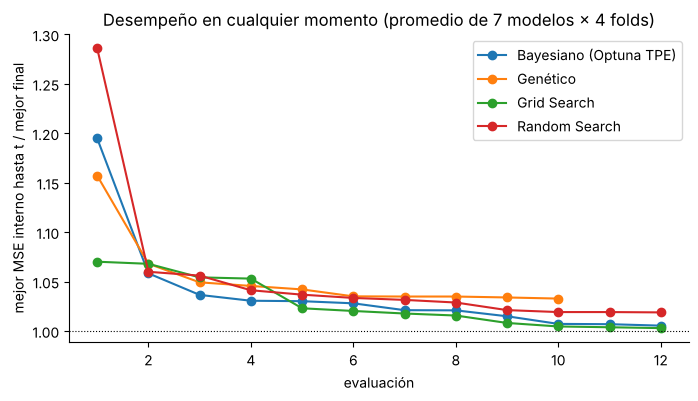

In [6]:
an = pd.read_csv(R + "e2_anytime.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8, 4))
for c in an.columns: ax.plot(an.index, an[c], marker="o", label=c)
ax.axhline(1, color="k", lw=.8, ls=":"); ax.set_xlabel("evaluación"); ax.set_ylabel("mejor MSE interno hasta t / mejor final")
ax.set_title("Desempeño en cualquier momento (promedio de 7 modelos × 4 folds)"); ax.legend(); plt.show()

In [7]:
dv = pd.read_csv(R + "e2_diversidad_genetica.csv").groupby("generacion").diversidad.agg(["mean", "std"])
print("Diversidad genética media por generación (desviación estándar de la población en el cubo unitario):"); dv.round(3)

Diversidad genética media por generación (desviación estándar de la población en el cubo unitario):


,mean,std
generacion,,
1,"0,226","0,045"
2,"0,144","0,058"
3,"0,104","0,053"


**Lectura.**

- **Con este presupuesto no hay un optimizador significativamente mejor.** La prueba de Friedman sobre los 28 bloques (7 modelos × 4 folds) no rechaza la igualdad (χ² = 0,39, p = 0,94). Los rangos medios van de 2,39 (Grid) a 2,61 (Genético).
- **El Bayesiano (TPE) arranca peor y termina igual.** Sus 4 primeras evaluaciones son aleatorias (exploración), por eso empieza 19,5 % por encima de su mejor final. Desde la evaluación 9 se acerca más rápido que Random Search y termina a 0,5 % del mejor, prácticamente igual que Grid (0,3 %).
- **El genético converge rápido, pero se queda corto.** La diversidad de su población cae de 0,23 a 0,10 en tres generaciones, una señal de convergencia prematura con solo 4 individuos. Termina a 3,3 % de su mejor y no fue el mejor optimizador en ningún modelo. Además usó 10 evaluaciones y no 12, porque el individuo élite no se vuelve a evaluar.
- **Por qué no se nota la ventaja teórica del Bayesiano y del genético:** los espacios tienen de 1 a 5 dimensiones y el presupuesto es de 12 evaluaciones. Con tan pocas dimensiones una malla bien puesta cubre bien el espacio, y el modelo sustituto del TPE apenas tiene datos para aprender. La ventaja de los métodos guiados aparece con más dimensiones o con más presupuesto; aquí no se observó, y se reporta así.

## Tiempos: complejidad teórica frente a la medida

In [8]:
t = comb.groupby("modelo")[["tiempo_entrenamiento_s", "tiempo_inferencia_s"]].mean().sort_values("tiempo_entrenamiento_s")
t["busqueda_total_min"] = comb.groupby("modelo").tiempo_busqueda_s.sum() / 60
t.round(3)

,tiempo_entrenamiento_s,tiempo_inferencia_s,busqueda_total_min
modelo,,,
KNN,"0,01","2,65","3,26"
Ridge,"0,02","0,01","0,06"
Lasso,"0,12","0,01","0,29"
Decision Tree,"0,21","0,01","0,49"
SVR,"1,24","0,05","1,96"
XGBoost,"2,41","0,04","6,31"
Random Forest,"5,20","0,09","12,89"


**Lectura.** Los tiempos medidos siguen el orden que anticipa la complejidad:

- **Entrenamiento.** Lineales y árbol: 0,2 s o menos. SVR con Nyström: 1,2 s, lejos del costo cuadrático del kernel exacto. XGBoost con histogramas: 2,4 s. Random forest: 5,2 s, el más costoso por sus 100 árboles.
- **Inferencia.** KNN invierte el patrón: entrena en 0,01 s pero tarda 2,7 s en predecir un fold, porque compara cada hora con todo el entrenamiento ($O(n\,p)$ por consulta).
- **Búsqueda.** El random forest consumió 12,9 de los 25,3 minutos de búsqueda de las 28 combinaciones.

## Las mejores combinaciones frente a ATER (prueba única 2025–2026)
Secuencia de la guía para regresión: **MCS** con todos los modelos (los 7 benchmarks del proyecto, las 7 mejores combinaciones del Entregable 2 y ATER), luego **Giacomini-White** y **Diebold-Mariano (HLN)** de ATER frente a cada mejor combinación, con ajuste de Holm sobre las 14 comparaciones, bootstrap estacionario para el intervalo y tamaño del efecto.

In [9]:
tp = pd.read_csv(R + "e2_prueba.csv"); tp[["modelo", "MSE", "MAPE", "AUC_pico", "CSI", "mejora_vs_persistencia_%", "p_MCS", "en_conjunto_10pct", "inferencia_s"]].round(3)

modelo,MSE,MAPE,AUC_pico,CSI,mejora_vs_persistencia_%,p_MCS,en_conjunto_10pct,inferencia_s
ATER (modelo original),2.256,"2,44","0,975","0,835","65,40","1,000",True,
E2 Random Forest (Grid Search),2.361,"2,56","0,974","0,824","63,79","0,002",False,"0,22"
E2 XGBoost (Random Search),2.448,"2,58","0,973","0,826","62,45","< 0,001",False,"0,07"
E2 SVR (Grid Search),2.596,"2,76","0,971","0,805","60,18","< 0,001",False,"0,12"
E2 KNN (Random Search),2.682,"2,77","0,971","0,814","58,88","< 0,001",False,"6,00"
E2 Ridge (Random Search),3.056,"3,01","0,965","0,795","53,13","< 0,001",False,"0,01"
E2 Lasso (Grid Search),3.079,"3,02","0,965","0,794","52,79","< 0,001",False,"0,01"
E2 Decision Tree (Bayesiano (Optuna TPE)),3.111,"3,02","0,966","0,800","52,28","< 0,001",False,"0,01"


In [10]:
mcs = pd.read_csv(R + "e2_mcs_todos.csv"); print("Model Confidence Set con los 15 modelos (alfa = 0,10):"); mcs.round(4)

Model Confidence Set con los 15 modelos (alfa = 0,10):


modelo,p_MCS,en_conjunto_10pct
Persistencia (misma hora de ayer),"< 0,001",False
E2 Decision Tree (Bayesiano (Optuna TPE)),"< 0,001",False
E2 Lasso (Grid Search),"< 0,001",False
Estacional (misma hora semana pasada),"< 0,001",False
Ridge (lineal),"< 0,001",False
E2 Ridge (Random Search),"< 0,001",False
Promedio por hora y día,"< 0,001",False
E2 KNN (Random Search),"< 0,001",False
Híbrido Ridge + XGBoost (residuo relativo),"< 0,001",False
E2 SVR (Grid Search),"< 0,001",False


In [11]:
pr = pd.read_csv(R + "e2_pruebas_vs_ater.csv")
pr[["prueba", "benchmark", "estadistico", "p_crudo", "p_holm", "mejora_MSE_pct", "IC95_lo", "IC95_hi", "delta_cliff_pareado", "d_cohen", "conclusion"]].round(4)

prueba,benchmark,estadistico,p_crudo,p_holm,mejora_MSE_pct,IC95_lo,IC95_hi,delta_cliff_pareado,d_cohen,conclusion
Diebold-Mariano (HLN),E2 Random Forest (Grid Search),"3,5","< 0,001","< 0,001","4,44","1,66","7,34","0,283","0,143",ATER mejor (rechaza H0)
Giacomini-White condicional,E2 Random Forest (Grid Search),"17,1","< 0,001","< 0,001","4,44","1,66","7,34","0,283","0,143",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),E2 XGBoost (Random Search),"4,7","< 0,001","< 0,001","7,86","5,16","10,33","0,283","0,178",ATER mejor (rechaza H0)
Giacomini-White condicional,E2 XGBoost (Random Search),"24,0","< 0,001","< 0,001","7,86","5,16","10,33","0,283","0,178",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),E2 KNN (Random Search),"7,1","< 0,001","< 0,001","15,87","12,51","19,66","0,424","0,301",ATER mejor (rechaza H0)
Giacomini-White condicional,E2 KNN (Random Search),"56,8","< 0,001","< 0,001","15,87","12,51","19,66","0,424","0,301",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),E2 SVR (Grid Search),"4,6","< 0,001","< 0,001","13,11","7,92","18,11","0,345","0,196",ATER mejor (rechaza H0)
Giacomini-White condicional,E2 SVR (Grid Search),"24,2","< 0,001","< 0,001","13,11","7,92","18,11","0,345","0,196",ATER mejor (rechaza H0)
Diebold-Mariano (HLN),E2 Lasso (Grid Search),"10,0","< 0,001","< 0,001","26,72","21,75","32,08","0,488","0,407",ATER mejor (rechaza H0)
Giacomini-White condicional,E2 Lasso (Grid Search),"95,4","< 0,001","< 0,001","26,72","21,75","32,08","0,488","0,407",ATER mejor (rechaza H0)


**Lectura.**

- **ATER gana a las 7 mejores combinaciones del Entregable 2 en la prueba 2025–2026.** Las más cercanas son el random forest (MSE 2.361; ATER reduce el error 4,4 %, IC 95 %: 1,7–7,3 %) y el XGBoost (2.448; reducción de 7,9 %, IC: 5,2–10,3 %).
- **Las pruebas lo confirman.** Giacomini-White y Diebold-Mariano rechazan la igualdad frente a las 7, con p ajustado por Holm < 0,001 en las 14 comparaciones.
- **En el MCS con los 15 modelos, ATER es otra vez el único sobreviviente.** El random forest del Entregable 2 queda fuera con p = 0,002.
- **Tamaño del efecto.** Frente a las combinaciones de árboles es pequeño (δ de Cliff pareado 0,28). Frente a KNN, SVR, Lasso, Ridge y el árbol de decisión es de mediano a grande (0,35 a 0,73).
- **Conclusión:** sumar las 28 combinaciones del Entregable 2 no cambia el veredicto de R3. ATER sigue siendo el mejor modelo con significancia estadística.